In [5]:
import os, sys
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

print("CWD:", os.getcwd())
print("sys.path[0]:", sys.path[0])
print("src exists:", (PROJECT_ROOT / "src").exists())
print("src/__init__.py exists:", (PROJECT_ROOT / "src" / "__init__.py").exists())

CWD: C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch
sys.path[0]: C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch
src exists: True
src/__init__.py exists: True


In [6]:
import os, sys
from pathlib import Path
os.chdir(Path(r"C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch"))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [7]:
from src.models.train import train_all
results = train_all()


Training logistic_regression...
  Train: acc=0.972, F1=0.971, AUC=0.997
  Test:  acc=0.967, F1=0.966, AUC=0.996

Training random_forest...
  Train: acc=0.978, F1=0.977, AUC=0.998
  Test:  acc=0.851, F1=0.849, AUC=0.944

Training xgboost...
  Train: acc=0.998, F1=0.998, AUC=1.000
  Test:  acc=0.944, F1=0.942, AUC=0.991

Saved metrics to results/tables/baseline_model_performance.csv


In [8]:
df = pd.read_csv('results/tables/baseline_model_performance.csv')
df

,model,train_accuracy,train_f1,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,logistic_regression,0.971875,0.970974,0.967292,0.964783,0.966885,0.965832,0.996488
1,random_forest,0.978073,0.977372,0.851458,0.824713,0.875381,0.849292,0.944065
2,xgboost,0.997708,0.997633,0.944375,0.945127,0.938126,0.941614,0.990706


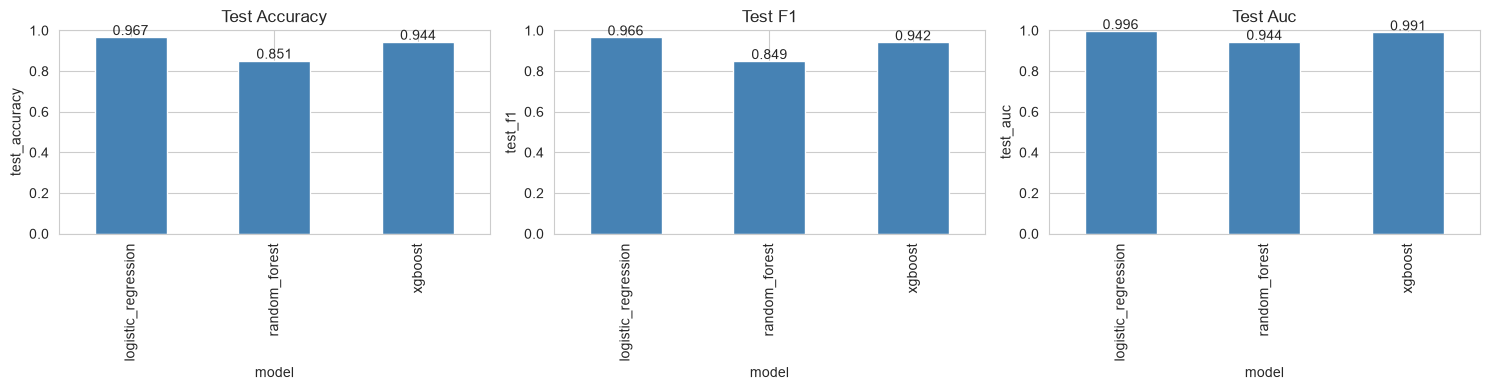

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, ['test_accuracy', 'test_f1', 'test_auc']):
    df.set_index('model')[metric].plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(metric.replace('test_', 'Test ').replace('_', ' ').title())
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    for i, v in enumerate(df[metric]):
        ax.text(i, v + 0.01, f"{v:.3f}", ha='center')

plt.tight_layout()
plt.savefig('results/figures/04_baseline_model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

### Interpretation

All three models achieve similar test performance on the Blind (unbiased) labels.
This is the baseline: **model performance when the training signal is fair.**

The key question for the next notebook is: **does model performance change
when the training signal is biased?** That comparison tells us whether
bias in labels translates into bias in model predictions.